In [1]:
nodes = ["Car-1", "Car-2", "Car-3", "Car-4", "Car-5", "Car-6", "Car-7", "Car-8", "Car-9", "BS-1", "BS-2"]
rates = {
    "Car-1": {"Car-2": 4, "Car-3": 4, "Car-4": 4, "Car-5": 3},
    "Car-2": {"Car-1": 4, "Car-4": 5, "BS-1": 6},
    "Car-3": {"Car-1": 4, "Car-6": 3},
    "Car-4": {"Car-1": 4, "Car-2": 5, "Car-5": 4, "Car-7": 1},
    "Car-5": {"Car-1": 3, "Car-4": 4, "Car-6": 5, "Car-7": 2, "Car-8": 7, "Car-9": 5},
    "Car-6": {"Car-3": 3, "Car-5": 5, "Car-9": 5},
    "Car-7": {"Car-4": 1, "Car-5": 2, "Car-8": 3, "BS-2": 6},
    "Car-8": {"Car-5": 7, "Car-7": 3, "Car-9": 4},
    "Car-9": {"Car-5": 4, "Car-6": 5, "Car-8": 4},
    "BS-1": {"Car-2": 6},
    "BS-2": {"Car-7": 6}
}

source = "Car-9"
base_stations = {"BS-1", "BS-2"}


In [ ]:
import heapq

def find_optimal_path(nodes, rates, source, base_stations):

    # Initialize dictionaries and lists for tracking information
    max_transmission_rate = {node: float('-inf') for node in nodes}
    max_transmission_rate[source] = float('inf')

    previous = {node: None for node in nodes}
    queue = [(-float('inf'), source)]  # Priority queue to store nodes based on transmission rate
    visited_nodes = []  # List to store visited nodes
    paths = {node: [] for node in nodes}  # Dictionary to store paths to each node

    # Main loop for Dijkstra's algorithm
    while queue:
        current_rate, current_node = heapq.heappop(queue)
        visited_nodes.append(current_node)  # Store the visited node

        # Check if the current node is a base station
        if current_node in base_stations:
            optimal_path = []
            node = current_node
            while node is not None:
                optimal_path.append(node)
                node = previous[node]
            optimal_path.reverse()
            return optimal_path, -current_rate, visited_nodes, paths

        # Explore neighbors and update transmission rates
        for neighbor, rate in rates[current_node].items():
            transmission_rate = min(max_transmission_rate[current_node], rate)

            # If a better transmission rate is found, update information and enqueue the neighbor
            if transmission_rate > max_transmission_rate[neighbor]:
                max_transmission_rate[neighbor] = transmission_rate
                previous[neighbor] = current_node
                heapq.heappush(queue, (-transmission_rate, neighbor))
                paths[neighbor] = paths[current_node] + [current_node]  # Store the path to the neighbor

    # Return empty lists if no optimal path is found
    return [], 0, visited_nodes, paths


In [ ]:
def reconstruct_path(previous_node, current_node):
    # Reconstruct the optimal path
    optimal_path = []
    node = current_node
    while node is not None:
        optimal_path.append(node)
        node = previous_node[node]
    optimal_path.reverse()
    return optimal_path

In [ ]:
optimal_path, max_end_to_end_transmission_rate, visited_nodes, paths = find_optimal_path(nodes, rates, source, base_stations)
print("Optimal Path to BS-1:", optimal_path)
print("Maximum End-to-End Transmission Rate:", max_end_to_end_transmission_rate)

print("Visited Nodes:", visited_nodes)
print("Paths:", paths)


Optimal Path to BS-1: ['Car-9', 'Car-6', 'Car-5', 'Car-4', 'Car-2', 'BS-1']
Maximum End-to-End Transmission Rate: 4
Visited Nodes: ['Car-9', 'Car-6', 'Car-5', 'Car-8', 'Car-4', 'Car-1', 'Car-2', 'BS-1']
Paths: {'Car-1': ['Car-9', 'Car-6', 'Car-5', 'Car-4'], 'Car-2': ['Car-9', 'Car-6', 'Car-5', 'Car-4'], 'Car-3': ['Car-9', 'Car-6', 'Car-5', 'Car-4', 'Car-1'], 'Car-4': ['Car-9', 'Car-6', 'Car-5'], 'Car-5': ['Car-9', 'Car-6'], 'Car-6': ['Car-9'], 'Car-7': ['Car-9', 'Car-6', 'Car-5', 'Car-8'], 'Car-8': ['Car-9', 'Car-6', 'Car-5'], 'Car-9': [], 'BS-1': ['Car-9', 'Car-6', 'Car-5', 'Car-4', 'Car-2'], 'BS-2': []}


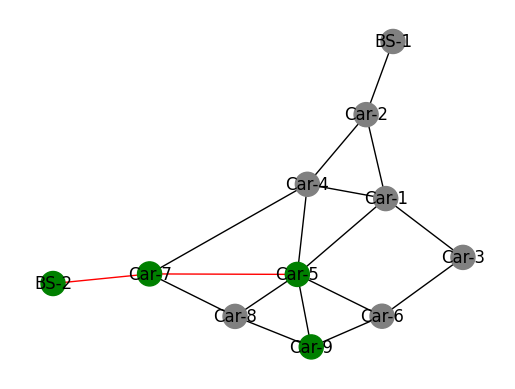

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph of the nodes and edges in the problem
G = nx.Graph()
G.add_nodes_from(nodes)
for node, edges in rates.items():
    for neighbor, weight in edges.items():
        G.add_edge(node, neighbor, weight=weight)

# Find the optimal path using Dijkstra's algorithm
path = nx.dijkstra_path(G, source, "BS-2")

# Highlight the optimal path in the graph
edge_colors = ["red" if (u, v) in zip(path, path[1:]) else "black" for u, v in G.edges()]
node_colors = ["green" if node in path else "gray" for node in G.nodes()]
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G, pos, node_color=node_colors)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors)
nx.draw_networkx_labels(G, pos)
plt.axis("off")
plt.show()


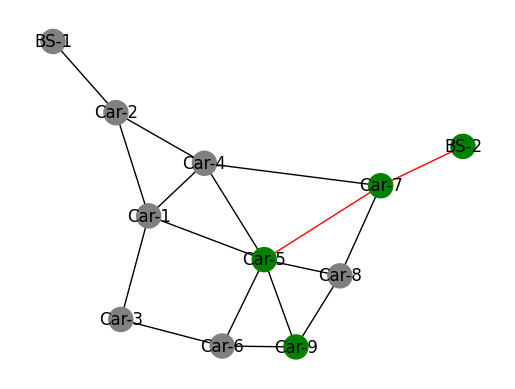

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph of the nodes and edges in the problem
G = nx.Graph()
G.add_nodes_from(nodes)
for node, edges in rates.items():
    for neighbor, weight in edges.items():
        G.add_edge(node, neighbor, weight=weight)

# Find the optimal path using Dijkstra's algorithm
path = nx.dijkstra_path(G, source, "BS-2")

# Highlight the optimal path in the graph
edge_colors = ["red" if (u, v) in zip(path, path[1:]) else "black" for u, v in G.edges()]
node_colors = ["green" if node in path else "gray" for node in G.nodes()]
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G, pos, node_color=node_colors)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors)
nx.draw_networkx_labels(G, pos)
plt.axis("off")
plt.show()
